# Analiza danych przestrzennych - ćwiczenia laboratoryjne 2025/2026

Ten notatnik zalicza się do grupy zestawów zadań, na podstawie których odbywa się zaliczenie ćwiczeń i podlega zwrotowi do oceny w ustalonym na zajęciach terminie.

Uwagi i wytyczne ogólne dotyczące uzupełniania i oceny notatnika:
- Podczas wykonywania zadań należy korzystać wyłącznie z pakietów zaimportowanych na początku notatnika oraz z pakietów wchodzących w skład standardowej biblioteki Pythona, które można zaimportować samodzielnie we wskazanej komórce notatnika.
- Swoje rozwiązania należy wprowadzać wyłącznie w miejce następujących fragmentów kodu:<br/> `# YOUR CODE HERE`<br/> `raise NotImplementedError()`<br/> 
a odpowiedzi tekstowe w komórkach oznaczonych hasłem:<br/> 
`YOUR ANSWER HERE`<br/> 
Nie należy w żaden sposób modyfikować pozostałych fragmentów kodu oraz innych elementów notatnika, w szczególności dodawać lub usuwać komórek oraz zmieniać nazwy pliku.
- Jeżeli zestaw zadań wymaga skorzystania z fragmentów kodu opracowanego w ramach wcześniejszych zestawów zadań należy je umieścić we wskazanej komórce notatnika.
- Otrzymywane wyniki i odpowiedzi mają być rezultatem wykonania napisanego kodu, odpowiedzi uzupełniane manualnie nie podlegają ocenie.
- Zawarte w notatniku automatyczne testy mają charakter poglądowy. Dotyczą one wybranych aspektów zadań i mają na celu wyłapać podstawowe błędy. Przejście przez kod wszystkich testów nie oznacza, że zadanie jest wykonane w całości poprawnie i zostanie ocenione na maksymalną liczbę punktów.
- Zadania należy wykonać w taki sposób, aby podczas wykonywania kodu nie zostały wyświetlone żadne ostrzeżenia.
- Zadania, które powodują wyświetlenie komunikatu o błędzie przerywającym wykonywanie kodu nie podlegają ocenie.
- W treści niektórych zadań mogą znaleźć się przykładowe schematy ich rozwiązania lub przykładowe schematy istotnych części rozwiązania. Nie zawsze są to rozwiązania optymalne pod kątem długości kodu lub prostoty rozwiązania.  Ich celem jest klarowne rozbicie pracy na kroki i ułatwienie samodzielnej weryfikacji wyników na każdym etapie. Należy je traktować wyłącznie poglądowo, a nie jako jedyne dopuszczalne rozwiązania. Ocenie podlega poprawność merytoryczna rozwiązania, jego kompletność oraz zgodność z wymaganiami, a nie konkretna forma zapisu.
- Dla zachowania przejrzystości i łatwego odnajdywania informacji w treści zadań podawane są pełne nazwy funkcji i klas wraz z nazwami pakietów (np. `pandas.read_csv()`, `geopandas.GeoDataFrame.to_crs`). W notatniku te same obiekty są dostępne przez skrótowe aliasy (np. `pd.read_csv()`, `gpd.GeoDataFrame.to_crs`).

Uwagi i wytyczne ogólne dotyczące wizualizacji wyników:
- Wszystkie wykresy powinny być wykonane w jednolitym, przejrzystym i czytelnym stylu, posiadać odpowiednio dobrane proporcje i zakresy wartości osi.
- Figury powinny mieć ustawione białe tło, tak, aby niezależnie od ustawień notatnika wszystkie elementy wykresów były dobrze widoczne (domyślnie tło jest przeźroczyste co może powodować problemy w notatnikach z ustawionym ciemnym tłem). Rozmiar poziomy figur nie powinien przekraczać 20 cali.
- Wykresy oraz ich osie powinny mieć nadane tytuły. Jeżeli w obrębie figury znajduje się więcej niż jeden wykres to figura również powinna mieć nadany tytuł.

Przed odesłaniem zestawu zadań do oceny proszę uzupełnić komórkę z danymi autorów rozwiązania (nazwa zespołu oraz imiona, nazwiska i numery indeksów członków zespołu) oraz upewnić się, że notatnik działa zgodnie z oczekiwaniami. W tym celu należy skorzystać z opcji **Restart Kernel and Run All Cells...** dostępnej na górnej belce notatnika pod symbolem $\blacktriangleright\blacktriangleright$.

Nazwa zespołu: GIN12  
Członkowie:  
Michał Kuśnierz 426683,  
Tymoteusz Chrzan 426173,  
Tymoteusz Hajduk 428250

---

## Zestaw zadań 8: Badanie intensywności procesów punktowych oraz relacji między punktami (część 2)

In [1]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [2]:
# Miejsce do importu pakietów wchodzących w skład standardowej biblioteki Pythona oraz ustawienie opcji wykorzystywanych pakietów

### Wczytanie danych
Poniższy kod wczytuje do zmiennych `poland`, `points_1`, `points_2`, `points_3` oraz `test_points` dane z pliku data.gpkg.

In [3]:
poland = gpd.read_file("data.gpkg", layer='poland')
poland

,Nazwa,geometry
0,Polska,"POLYGON ((495817.822 183473.276, 495778.757 18..."


In [4]:
points_1 = gpd.read_file("data.gpkg", layer='points_R')
points_1.head()

,geometry
0,POINT (746726.814 164535.535)
1,POINT (561669.012 179254.158)
2,POINT (575522.076 176268.791)
3,POINT (727348.477 178177.739)
4,POINT (749495.901 176165.143)


In [5]:
points_2 = gpd.read_file("data.gpkg", layer='points_P')
points_2.head()

,geometry
0,POINT (458336.668 682611.54)
1,POINT (264451.331 421768.917)
2,POINT (716458.063 211411.884)
3,POINT (333437.357 309193.537)
4,POINT (438396.636 631242.241)


In [6]:
points_3 = gpd.read_file("data.gpkg", layer='points_T')
points_3.head()

,geometry
0,POINT (638062.941 689433.083)
1,POINT (625542.51 692000.369)
2,POINT (638701.807 697065.653)
3,POINT (649499.586 696696.79)
4,POINT (650911.338 705624.982)


In [7]:
test_points = gpd.read_file("data.gpkg", layer='test_points')
test_points.head()

,geometry
0,POINT (364732.092 723385.55)
1,POINT (309246.986 665351.724)
2,POINT (352441.728 328023.909)
3,POINT (330186.768 278858.464)
4,POINT (338057.193 310040.858)


### Miejsce na wklejenie funkcji ze wcześniejszych zestawów

Jedno z rozwiązań będzie wymagało skorzystania z funkcji `homogeneous_poisson_pp()` przygotowanej w ramach zestawu zadań 6. Przeklej swoje rozwiązanie do poniższej komórki.

In [8]:
def homogeneous_poisson_pp(polygon, crs, intensity):
    
    minx, miny, maxx, maxy = polygon.bounds
    A = (maxx - minx) * (maxy - miny)

    N = np.random.poisson(intensity * A)

    Xf = minx + (maxx - minx) * np.random.rand(N)
    Yf = miny + (maxy - miny) * np.random.rand(N)

    gdf = gpd.GeoDataFrame(geometry=gpd.points_from_xy(Xf, Yf), crs=crs)
    gdf = gdf[gdf.geometry.within(polygon)].reset_index(drop=True)

    return gdf
    
    """
    Parameters
    -------
    polygon: shapely.geometry.polygon.Polygon
        Geometria poligonu, w obrębie którego mają zostać wygenerowane punkty.
    crs: str, int, pyproj.crs.crs.CRS
        Układ odniesienia przypisany do wynikowego GeoDataFrame. Powinien odpowiadać układowi współrzędnych wejściowego poligonu.
    intensity: float
        Liczba dodatnia określająca intensywność procesu punktowego.

    Returns
    -------
    points : geopandas.GeoDataFrame
        Tablica zawierająca punkty w układzie odniesienia `crs`, ograniczone wyłącznie do obszaru wejściowego poligonu.
    """

### Uwagi do wykonania zadań
We wszystkich zadaniach należy przyjąć, że pracujemy w płaskim układzie współrzędnych (układzie odniesienia opartym na odwzorowaniu kartograficznym na płaszczyznę). Dołączona do zestawu zadań tablice z rozkładami punktów oraz z granicami Polski zapisane są w układzie EPSG:2180.

### Zadanie 1: Teoretyczne funkcje G i F jednorodnego rozkładu Poissona [2 pkt]

Przygotuj funkcję `gf_function_poisson()`, która będzie generować dane niezbędne do wykonania wykresu teoretycznej funkcji G lub F (w zależności od przyjętej wartości parametru) jednorodnego rozkładu Poissona o zadanej intensywności.

Algorytm postępowania:

1. Korzystając z funkcji `numpy.exp()` oraz stałej `numpy.pi` oblicz wartości funkcji G/F dla zadanych odległości:
$G(d) = F(d) = 1 - exp(-\lambda \pi d^2)$<br/>
gdzie: $\lambda$ - intensywność procesu, $d$ - odległość.

2. Zbuduj obiekt `pandas.DataFrame` zawierające odpowiednio podpisane kolumny z odległościami i wyliczonymi wartościami funkcji G lub F.

3. Zwróć tablicę.

In [9]:
"""
    Parameters
    -------
    d: numpy.ndarray
        Macierz zawierająca uszeregoane rosnąco odległości, dla których ma zostać wyznaczona wartość funkcji G.
    intensity: float
        Liczba dodatnia określająca intensywność jednorodnego procesu Poissona.
    function: str
        "G" lub "F" w zależności od tego, która funkcja ma być zwrócona.
    Returns
    -------
    gf_function: DataFrame
        Tablica zawierająca dwie kolumny:
        - 'D' - zawierającą uszeregoane rosnąco wartości odległości do najbliższego sąsiada, dla których wyliczone zostały wartości funkcji G lub F,
        - 'G' lub 'F' - zawierającą wyliczone wartości funkcji G lub "F".
    """

def gf_function_poisson(d, intensity, function):
    values = 1 - np.exp(-intensity * np.pi * d**2)
    col = function.upper()
    df = pd.DataFrame({"D": d, col: values})
    return df

In [10]:
# Komórka testowa
test_result_1 = gf_function_poisson(np.arange(11), 0.05, "G")
assert type(test_result_1) == pd.DataFrame
assert test_result_1.shape == (11, 2)
assert set(test_result_1.columns) == set(['D', "G"])
assert np.all(np.isclose(test_result_1.min().values, np.array([0., 0.])))
assert np.all(np.isclose(test_result_1.mean().values, np.array([5., 0.75126655])))
assert np.all(np.isclose(test_result_1.max().values, np.array([10., 0.99999985])))

test_result_2 = gf_function_poisson(np.arange(11), 0.05, "F")
assert type(test_result_2) == pd.DataFrame
assert test_result_2.shape == (11, 2)
assert set(test_result_2.columns) == set(['D', "F"])
assert np.all(np.isclose(test_result_2.min().values, np.array([0., 0.])))
assert np.all(np.isclose(test_result_2.mean().values, np.array([5., 0.75126655])))
assert np.all(np.isclose(test_result_2.max().values, np.array([10., 0.99999985])))

### Zadanie 2: Funkcja G [12 pkt]

#### a) Przygotowanie funkcji

Przygotuj funkcję `g_function()`, która będzie generować dane niezbędne do wykonania wykresu funkcji G analizowanego rozkładu punktów.

Algorytm postępowania:
1. Korzystając z własności `geopandas.GeoDataFrame.geometry.x` i `geopandas.GeoDataFrame.geometry.y` wyodrębnij z geometrii rozkładu współrzędne X i Y poszczególnych punktów. Następnie korzystajac z `numpy.vstack()` oraz transpozycji lub `numpy.concatenate()` skonstruuj macierz współrzędnych o wymiarach `(n, 2)`, gdzie n to liczba punktów rozkładu.

2. Korzystając z `scipy.spatial.distance.pdist()` (obliczenie odległości) oraz `scipy.spatial.distance.squareform()` (konwersja wyniku do macierzy 2D) oblicz odległości między wszystkimi parami punktów.

3. Korzystając z `numpy.sort()` posortuj wszystkie wiersze lub kolumny macierzy rosnąco (macierz jest symetryczna):
   - pierwsza wartość to odległość punktu do samego siebie (zawsze 0),
   - druga wartość to odległość do najbliższego sąsiada.

4. Wyodrębnij wektor odległości do najbliższego sąsiada - druga kolumna lub wiersz w zależności od przyjętego kierunku sortowania.

5. Jeśli `support` jest liczbą całkowitą, utwórz macierz zawierający równomiernie rozmieszczone wartości od 0 do największej zmierzonej odległości do najbliższego sąsiada przy użyciu `numpy.linspace()` lub `numpy.arange()`. Jeżeli `support` jest macierzą nie ma konieczności wykonywania tego kroku.

5. Skonstruuj funkcję G jako dystrybuantę rozkładu odległości: <br/>
    $G(d) = \frac{n_{d_{min} \le d}}{n}$  <br/>
    gdzie: $n_{d_{min} \le d}$ - liczba punktów, dla których odległość do najbliższego sąsiada $d_{min}$ jest mniejsza lub równa $d$, $n$ - liczba punktów.

6. Zwróć wynik w postaci `pandas.DataFrame` z kolumnami 'D' – wartości odległości i 'G' – obliczone wartości funkcji G.

In [11]:
"""
    Parameters
    ----------
    points : geopandas.GeoDataFrame
        Zbiór punktów analizowangeo procesu punktowego.
    support : int lub numpy.ndarray
        Jeśli int – liczba punktów siatki w zakresie [0, max(d_nn)].
        Jeśli numpy.ndarray – konkretne wartości odległości, dla których funkcja G ma zostać obliczona.

    Returns
    -------
    g: pandas.DataFrame
        Tablica danych z kolumnami:
        - 'D' : wartości odległości,
        - 'G' : wartości empirycznej funkcji G.
    """

def g_function(points, support=100):
    x = points.geometry.x.values
    y = points.geometry.y.values
    coords = np.vstack((x, y)).T
    dist_matrix = sp.spatial.distance.squareform(sp.spatial.distance.pdist(coords))
    dist_sorted = np.sort(dist_matrix, axis=1)
    d_nn = dist_sorted[:, 1]
    if isinstance(support, int):
        D = np.linspace(0, d_nn.max(), support)
    else:
        D = support
    G = np.array([np.sum(d_nn <= d)/len(d_nn) for d in D])
    return pd.DataFrame({"D": D, "G": G})

In [12]:
# Komórka testowa
test_result_3 = g_function(test_points, support=50)

assert type(test_result_3) == pd.DataFrame
assert test_result_3.shape == (50, 2)
assert set(test_result_3.columns) == set(['D', "G"])
assert np.all(np.isclose(test_result_3.min().values, np.array([0., 0.])))
assert np.all(np.isclose(test_result_3.mean().values, np.array([4.23136208e+04, 8.88040886e-01])))
assert np.all(np.isclose(test_result_3.max().values, np.array([8.46272416e+04, 1.00000000e+00])))

#### b) Zastosowanie funkcji i wizualizacja wyniku

Wykorzystaj przygotowane wcześniej funkcje `g_function()` i `gf_function_poisson()` do zbadania relacji przestrzennych pomiędzy punktami wszystkich wczytanych do notatnika rozkładów (`points_1`, `points_2`, `points_3`). Celem zadania jest porównanie empirycznych funkcji G dla trzech różnych rozkładów z ich teoretycznymi odpowiednikami dla jednorodnego rozkładu Poissona. W tym celu dla każdego z rozkładów wyznacz:
 - empiryczną funkcję G analizowanego rozkładu; 
 - teoretyczną funkcję G jednorodnego rozkładu Poissona.
Wyznaczając teoretyczną funkcję G podaj tę samą siatkę odległości, jaka została użyta przy wyznaczaniu empirycznej funkcji G oraz intensywność równą liczbie punktów analizowanego rozkładu podzieloną przez pole powierzchni poligonu, na którym analizowany jest rozkład.

Następnie, korzystając z funkcji pakietu matplotlib i seaborn oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wyniki na pojedynczej figurze (siatka wykresów 2x3).

W górnym rzędzie przedstaw analizowane rozkłady punktów. Wizualizacja dla każdego rozkładu powinna zawierać:
    
- granice poligonu, w obrębie którego prowadzona jest analiza,
- rozkład punktowy, który został poddany analizie.

W dolnym wierszu umieść wykresy porównawcze empirycznej funkcji G analizowanego rozkładu oraz teoretycznej funkcji G jednorodnego procesu Poissona. Wizualizacja dla każdego rozkładu powinna zawierać:
    
- wykres schodkowy (steps-post) funkcji empirycznej (`seaborn.lineplot()` lub `matplotlib.pyplot.step()`),
- gładki wykres funkcji teoretycznej (`seaborn.lineplot()` lub `matplotlib.pytplot.plot()`).

Dla wszystkich wykresów w dolnym rzędzie figury ustaw identyczny zakres osi X oparty na największej wartości odległości spośród trzech funkcji G.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowane wykresy były przejrzyste i czytelne.

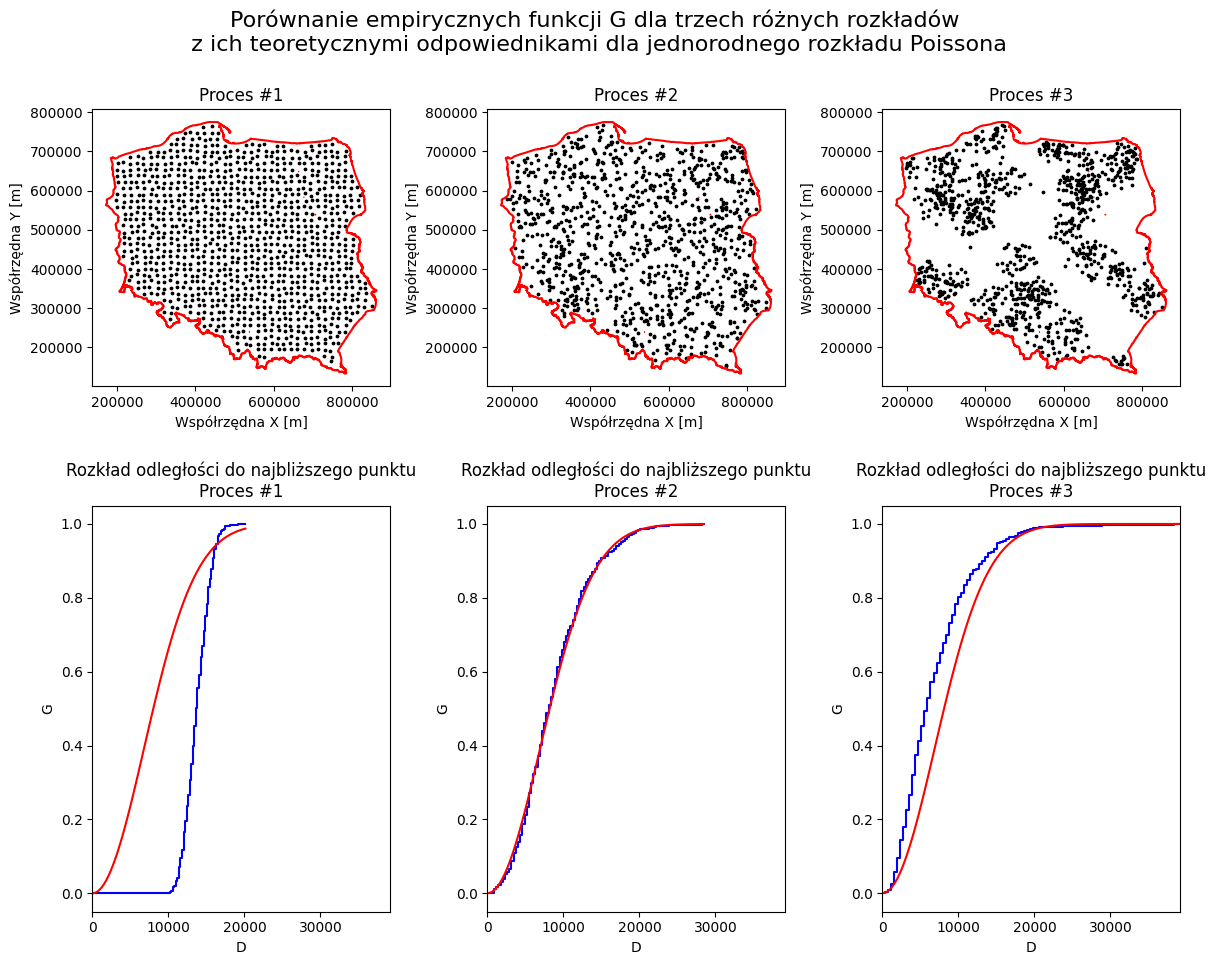

In [13]:
g1 = g_function(points_1, support=100)
g2 = g_function(points_2, support=100)
g3 = g_function(points_3, support=100)

area = poland.geometry.area.values[0]

intensity_1 = len(points_1) / area
intensity_2 = len(points_2) / area
intensity_3 = len(points_3) / area

g_theoretical_1 = gf_function_poisson(g1["D"].values, intensity_1, "G")
g_theoretical_2 = gf_function_poisson(g2["D"].values, intensity_2, "G")
g_theoretical_3 = gf_function_poisson(g3["D"].values, intensity_3, "G")

max_x = max(g1["D"].max(), g2["D"].max(), g3["D"].max())

fig, ax = plt.subplots(2, 3, figsize=(12, 10))
fig.suptitle("Porównanie empirycznych funkcji G dla trzech różnych rozkładów\n z ich teoretycznymi odpowiednikami dla jednorodnego rozkładu Poissona", 
             fontsize=16, y=0.96)

poland.boundary.plot(ax=ax[0, 0], color = "red")
poland.boundary.plot(ax=ax[0, 1], color = "red")
poland.boundary.plot(ax=ax[0, 2], color = "red")

points_1.plot(ax=ax[0, 0], markersize=3, color="black")
points_2.plot(ax=ax[0, 1], markersize=3, color="black")
points_3.plot(ax=ax[0, 2], markersize=3, color="black")

sns.lineplot(x=g1["D"], y=g1["G"], ax=ax[1, 0], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_theoretical_1["D"], y=g_theoretical_1["G"], ax=ax[1, 0], color="red")

sns.lineplot(x=g2["D"], y=g2["G"], ax=ax[1, 1], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_theoretical_2["D"], y=g_theoretical_2["G"], ax=ax[1, 1], color="red")

sns.lineplot(x=g3["D"], y=g3["G"], ax=ax[1, 2], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_theoretical_3["D"], y=g_theoretical_3["G"], ax=ax[1, 2], color="red")

ax[0, 0].set_xlabel("Współrzędna X [m]")
ax[0, 0].set_ylabel("Współrzędna Y [m]")
ax[0, 1].set_xlabel("Współrzędna X [m]")
ax[0, 1].set_ylabel("Współrzędna Y [m]")
ax[0, 2].set_xlabel("Współrzędna X [m]")
ax[0, 2].set_ylabel("Współrzędna Y [m]")

ax[0, 0].set_title("Proces #1")
ax[0, 1].set_title("Proces #2")
ax[0, 2].set_title("Proces #3")

ax[1, 0].set_title("Rozkład odległości do najbliższego punktu\nProces #1")
ax[1, 1].set_title("Rozkład odległości do najbliższego punktu\nProces #2")
ax[1, 2].set_title("Rozkład odległości do najbliższego punktu\nProces #3")

ax[1, 0].set_xlim(0, max_x)
ax[1, 1].set_xlim(0, max_x)
ax[1, 2].set_xlim(0, max_x)

plt.tight_layout()
plt.show()

### Zadanie 3: Funkcja F [12 pkt]

#### a) Przygotowanie funkcji

Przygotuj funkcję `f_function()`, która będzie generować dane niezbędne do wykonania wykresu funkcji F analizowanego rozkładu punktów.

Algorytm postępowania:

1. Skorzystaj z funkcji `homogeneous_poisson_pp()` do wygenerowania w obrębie zadanego poligonu pomiarowego rozkładu punktów o zadanej intensywności.

2. Korzystając z własności `geopandas.GeoDataFrame.geometry.x` i `geopandas.GeoDataFrame.geometry.y` wyodrębnij z geometrii rozkładów współrzędne X i Y poszczególnych punktów. Następnie korzystajac z `numpy.vstack()` oraz transpozycji lub `numpy.concatenate()` skonstruuj macierze współrzędnych o wymiarach `(n, 2)` i `(m, 2)`, gdzie `n` i `m` to odpowiednio liczby punktów w rozkładzie analizowanym i pomiarowego.

3. Skorzystaj z `scipy.spatial.distance.cdist()` aby otrzymać macierz odległości o wymiarach `(m, n)`:
   - każdy wiersz odpowiada punktowi pomiarowego,
   - każda kolumna odpowiada punktowi analizowanemu.

4. Korzystając z funkcji `numpy.min()` policz dla każdego z punktów rozkładu pomiarowego odległość do jego najbliższego sąsiada z analizowanego rozkładu. W tym celu ustaw odpowiednio wartość argumentu `axis`.

5. Jeśli `support` jest liczbą całkowitą, utwórz macierz zawierający równomiernie rozmieszczone wartości od 0 do największej odległości do najbliższego sąsiada przy użyciu `numpy.linspace()` lub `numpy.arange()`. Jeżeli `support` jest macierzą nie ma konieczności wykonywania tego kroku.

5. Skonstruuj funkcję F jako dystrybuantę rozkładu odległości: <br/>
    $F(d) = \frac{n_{d_{min} \le d}}{n}$  <br/>
    gdzie: $n_{d_{min} \le d}$ - liczba punktów rozkładu pomiarowego, dla których odległość do najbliższego sąsiada z analizowanego rozkładu $d_{min}$ jest mniejsza lub równa $d$, $n$ - liczba punktów rozkładu pomiarowego.

6. Zwróć wynik w postaci `pandas.DataFrame` z kolumnami 'D' – wartości odległości i 'F' – obliczone wartości funkcji F.

In [14]:
"""
    Parameters
    ----------
    points : geopandas.GeoDataFrame
        Zbiór punktów analizowangeo procesu punktowego.
    polygon: shapely.geometry.polygon.Polygon
        Geometria poligonu ograniczającego analizowany obszar.
        Powinien mieć crs identyczny z crs wejściowego rozkładu punktów.
    intensity_test : float
        Intensywność jednorodnego procesu Poissona generującego punkty testowe.
    support : int lub numpy.ndarray
        Jeśli int – liczba punktów siatki w zakresie [0, max(d_nn)].
        Jeśli numpy.ndarray – konkretne wartości odległości, na których funkcja G ma zostać obliczona.

    Returns
    -------
    f: pandas.DataFrame
        Dane do wykresu funkcji F, zawierające kolumny:
        - 'D': wartości odległości,
        - 'F': wartości empirycznej funkcji F.
    """

def f_function(points, polygon, intensity_test, support=100):
    test_points = homogeneous_poisson_pp(polygon, points.crs, intensity_test)
    coords_points = np.vstack((points.geometry.x.values, points.geometry.y.values)).T
    coords_test = np.vstack((test_points.geometry.x.values, test_points.geometry.y.values)).T
    dist_matrix = sp.spatial.distance.cdist(coords_test, coords_points)
    d_min = np.min(dist_matrix, axis=1)
    if isinstance(support, int):
        D = np.linspace(0, d_min.max(), support)
    else:
        D = support
    F = np.array([np.sum(d_min <= d)/len(d_min) for d in D])
    return pd.DataFrame({"D": D, "F": F})

In [15]:
# Komórka testowa
test_result_4 = f_function(test_points, polygon=poland.geometry[0], intensity_test=0.0000001, support=50)

assert type(test_result_4) == pd.DataFrame
assert test_result_4.shape == (50, 2)
assert set(test_result_4.columns) == set(['D', "F"])
assert np.all(np.isclose(test_result_4.min().values, np.array([0., 0.])))

#### b) Zastosowanie funkcji i wizualizacja wyniku

Wykorzystaj przygotowane wcześniej funkcje `f_function()` i `gf_function_poisson()` do zbadania relacji przestrzennych pomiędzy punktami wszystkich wczytanych do notatnika rozkładów (`points_1`, `points_2`, `points_3`). Celem zadania jest porównanie empirycznych funkcji F dla trzech różnych rozkładów z ich teoretycznymi odpowiednikami dla jednorodnego rozkładu Poissona. W tym celu dla każdego z rozkładów wyznacz:
- empiryczną funkcję F analizowanego rozkładu; 
- teoretyczną funkcję F jednorodnego rozkładu Poissona.

Wyznaczając empiryczną funkcję F analizowanego rozkładu ustaw intensywność procesu pomiarowego na 0.0000001.
Wyznaczając teoretyczną funkcję F podaj tę samą siatkę odległości, jaka została użyta przy wyznaczaniu empirycznej funkcji F oraz intensywność równą liczbie punktów analizowanego rozkładu podzieloną przez pole powierzchni poligonu, na którym analizowany jest rozkład.

Następnie, korzystając z funkcji pakietu matplotlib i seaborn oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wyniki na pojedynczej figurze (siatka wykresów 2x3).

W górnym rzędzie przedstaw analizowane rozkłady. Wizualizacja dla każdego rozkładu powinna zawierać:

- granice poligonu, w obrębie którego prowadzona jest analiza,
- rozkład punktowy, który został poddany analizie.

W dolnym wierszu umieść wykresy porównawcze empirycznej funkcji F analizowanego rozkładu oraz teoretycznej funkcji F jednorodnego procesu Poissona. Wizualizacja dla każdego rozkładu powinna zawierać:

- wykres schodkowy (steps-post) funkcji empirycznej (`seaborn.lineplot()` lub `matplotlib.pyplot.step()`),
- gładki wykres funkcji teoretycznej (`seaborn.lineplot()` lub `matplotlib.pytplot.plot()`).
    
Dla wszystkich wykresów w dolnym rzędzie figury ustaw identyczny zakres osi X oparty na największej wartości odległości spośród trzech funkcji F.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowane wykresy były przejrzyste i czytelne.

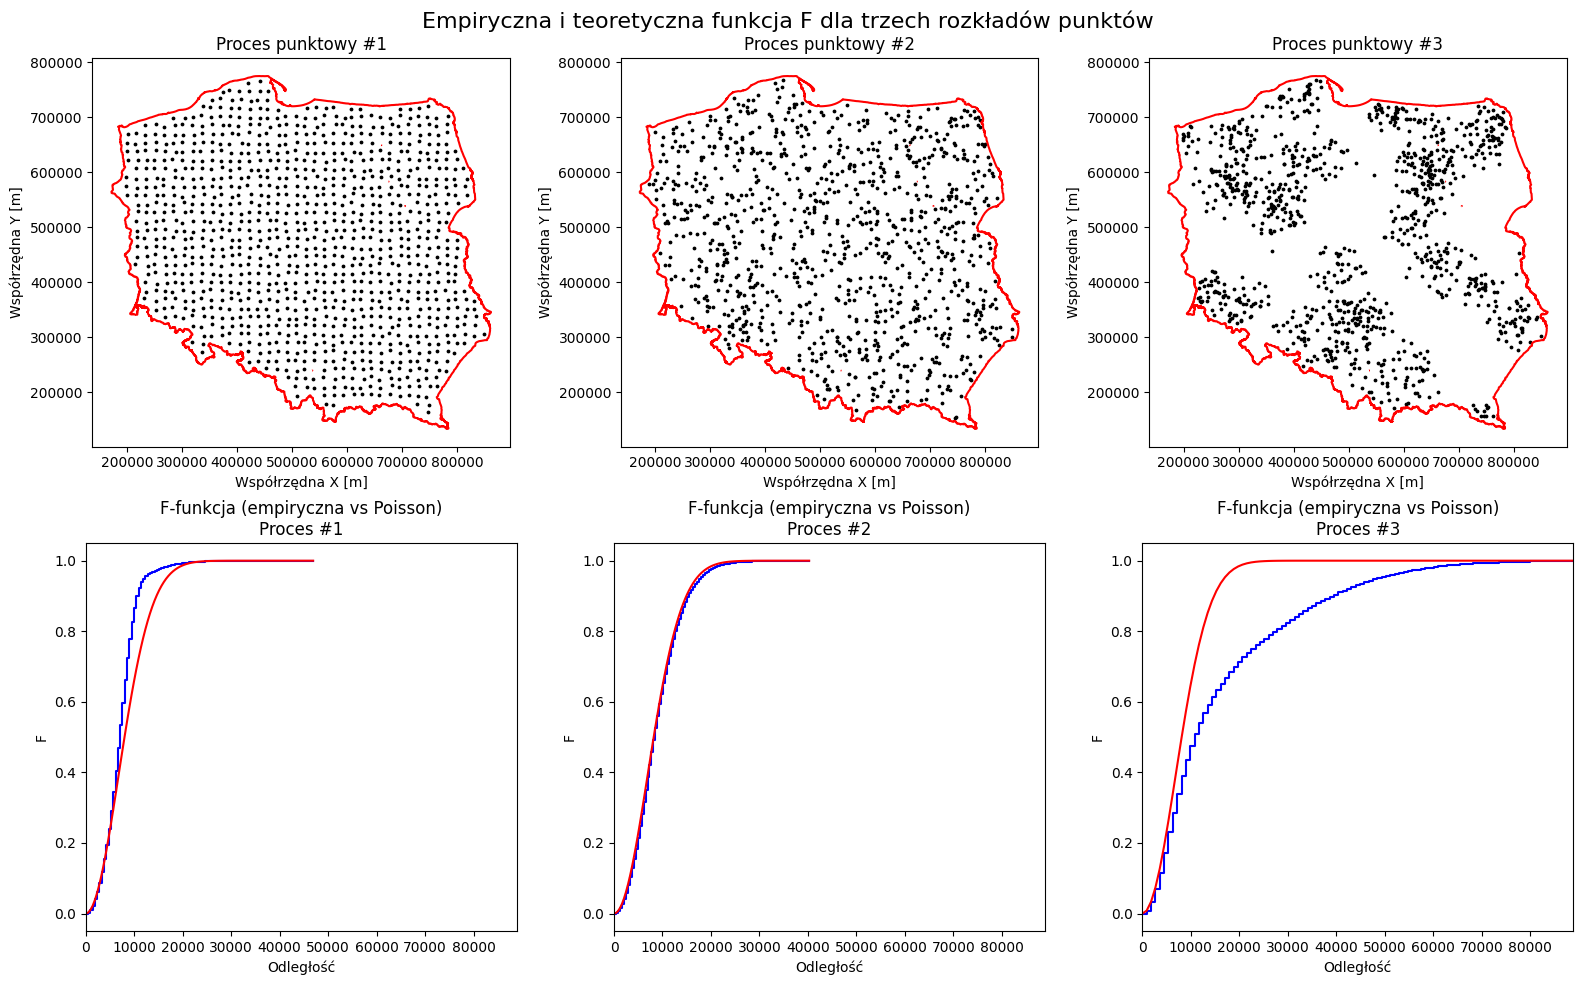

In [16]:
f1 = f_function(points_1, poland.geometry.values[0], intensity_test=0.0000001, support=100)
f2 = f_function(points_2, poland.geometry.values[0], intensity_test=0.0000001, support=100)
f3 = f_function(points_3, poland.geometry.values[0], intensity_test=0.0000001, support=100)

area = poland.geometry.area.values[0]
intensity_1 = len(points_1) / area
intensity_2 = len(points_2) / area
intensity_3 = len(points_3) / area

f_theoretical_1 = gf_function_poisson(f1["D"].values, intensity_1, "F")
f_theoretical_2 = gf_function_poisson(f2["D"].values, intensity_2, "F")
f_theoretical_3 = gf_function_poisson(f3["D"].values, intensity_3, "F")

max_x = max(f1["D"].max(), f2["D"].max(), f3["D"].max())

fig, ax = plt.subplots(2, 3, figsize=(16, 10))

poland.boundary.plot(ax=ax[0, 0], color = "red")
poland.boundary.plot(ax=ax[0, 1], color = "red")
poland.boundary.plot(ax=ax[0, 2], color = "red")

points_1.plot(ax=ax[0, 0], markersize=3, color="black")
points_2.plot(ax=ax[0, 1], markersize=3, color="black")
points_3.plot(ax=ax[0, 2], markersize=3, color="black")

sns.lineplot(x=f1["D"], y=f1["F"], ax=ax[1, 0], drawstyle="steps-post", color="blue")
sns.lineplot(x=f_theoretical_1["D"], y=f_theoretical_1["F"], ax=ax[1, 0], color="red")

sns.lineplot(x=f2["D"], y=f2["F"], ax=ax[1, 1], drawstyle="steps-post", color="blue")
sns.lineplot(x=f_theoretical_2["D"], y=f_theoretical_2["F"], ax=ax[1, 1], color="red")

sns.lineplot(x=f3["D"], y=f3["F"], ax=ax[1, 2], drawstyle="steps-post", color="blue")
sns.lineplot(x=f_theoretical_3["D"], y=f_theoretical_3["F"], ax=ax[1, 2], color="red")

ax[0, 0].set_title("Proces punktowy #1")
ax[0, 1].set_title("Proces punktowy #2")
ax[0, 2].set_title("Proces punktowy #3")

ax[1, 0].set_title("F-funkcja (empiryczna vs Poisson)\nProces #1")
ax[1, 1].set_title("F-funkcja (empiryczna vs Poisson)\nProces #2")
ax[1, 2].set_title("F-funkcja (empiryczna vs Poisson)\nProces #3")

ax[0, 0].set_xlabel("Współrzędna X [m]")
ax[0, 1].set_xlabel("Współrzędna X [m]")
ax[0, 2].set_xlabel("Współrzędna X [m]")
ax[0, 0].set_ylabel("Współrzędna Y [m]")
ax[0, 1].set_ylabel("Współrzędna Y [m]")
ax[0, 2].set_ylabel("Współrzędna Y [m]")

ax[1, 0].set_xlim(0, max_x)
ax[1, 1].set_xlim(0, max_x)
ax[1, 2].set_xlim(0, max_x)

ax[1, 0].set_xlabel("Odległość")
ax[1, 1].set_xlabel("Odległość")
ax[1, 2].set_xlabel("Odległość")
ax[1, 0].set_ylabel("F")
ax[1, 1].set_ylabel("F")
ax[1, 2].set_ylabel("F")

fig.suptitle("Empiryczna i teoretyczna funkcja F dla trzech rozkładów punktów", fontsize=16)
plt.tight_layout()
plt.show()

### Zadanie 4: Symulacja Monte Carlo na przykładzie funkcji G [12 pkt]

#### a) Przygotowanie funkcji

Przygotuj funkcję `g_function_monte_carlo()`, która przeprowadzi symulacyjny test Monte Carlo dla funkcji G.  

Algorytm postępowania:

1. Korzystając z przygotowanej w zadaniu 2 funkcji `g_function` oblicz funkcję G analizowanego rozkładu punktów.

2. Wyznacz intensywność analizowanego rozkładu punktów w obrębie poligonu (liczba punktów podzielona przez pole powierzchni obszaru).

3. Przeprowadź w pętli `for` założoną liczbę symulacji. Każdorazowo:
   - wygeneruj w obrębie poligonu jednorodny proces losowy Poissona o intensywności równej intensywności analizowanego rozkładu,
   - oblicz funkcję G zasymulowanego rozkładu na tej samej siatce odległości jak w przypadku analizowanego rozkładu (argument `support` jako macierz).

4. Zbierz wyniki w obrębie pojedynczej macierzy, a następnie wyznacz górną i dolną granicę obwiedni symulowanego procesu (odpowiednio minimalne i maksymalne wartości funkcji G dla każdej z odległości)

6. Zwróć wynik w postaci `pandas.DataFrame` zawierającej kolumny:
    - 'D' – siatka odległości,
    - 'G' – empiryczna funkcja G,
    - 'G_low' – dolna otoczka symulacyjna,
    - 'G_high' – górna otoczka symulacyjna.

In [17]:
"""
    Parameters
    ----------
    points : geopandas.GeoDataFrame
        Zbiór punktów analizowangeo procesu punktowego.
    polygon: shapely.geometry.polygon.Polygon
        Geometria poligonu ograniczającego analizowany obszar.
        Powinien mieć crs identyczny z crs wejściowego rozkładu punktów.
    nsim : int
         Liczba realizacji procesu CSR użytych do konstrukcji otoczek.
    support : int lub array
         Jeśli int — liczba punktów siatki d.
         Jeśli array-like — konkretne wartości odległości, na których G ma zostać obliczona.
    
    Returns
    -------
    G_MC: pandas.DataFrame
     Ramka danych zawierająca:
     - 'D': wartości odległości,
     - 'G': empiryczną funkcję G analizowanego rozkładu punktów,
     - 'G_low': dolną granica otoczki Monte Carlo,
     - 'G_high': górna granica otoczki Monte Carlo.
    """
def g_function_monte_carlo(points, polygon, support=100, nsim=99):
    g_empirical = g_function(points, support=support)
    intensity = len(points) / polygon.area
    sims = []
    for _ in range(nsim):
        sim_points = homogeneous_poisson_pp(polygon, points.crs, intensity)
        g_sim = g_function(sim_points, support=g_empirical["D"].values)
        sims.append(g_sim["G"].values)
    sims = np.array(sims)
    G_low = sims.min(axis=0)
    G_high = sims.max(axis=0)
    return pd.DataFrame({
        "D": g_empirical["D"],
        "G": g_empirical["G"],
        "G_low": G_low,
        "G_high": G_high})

In [18]:
# Komórka testowa
test_result_5 = g_function_monte_carlo(test_points, poland.geometry[0], support=50, nsim=10)

assert type(test_result_5) == pd.DataFrame
assert test_result_5.shape == (50, 4)
assert set(test_result_5.columns) == set(['D', "G", "G_low", "G_high"])
assert np.all(np.isclose(test_result_5.min().values, np.array([0., 0., 0., 0.])))

#### b) Zastosowanie funkcji i wizualizacja wyniku

Wykorzystaj przygotowaną wcześniej funkcję `g_function_monte_carlo()` do zbadania relacji przestrzennych pomiędzy punktami wszystkich wczytanych do notatnika rozkładów (`points_1`, `points_2`, `points_3`). Celem zadania jest porównanie empirycznych funkcji G dla trzech różnych rozkładów z wynikami symulacji Monte Carlo jednorodnego rozkładu Poissona. W tym celu dla każdego z rozkładów wykonaj test Monte Carlo przeprowadzający 99 symulacji.

Następnie, korzystając z funkcji pakietu matplotlib i seaborn oraz funkcji `geopandas.GeoDataFrame.plot()` zwizualizuj wyniki na pojedynczej figurze (siatka wykresów 2x3).

W górnym rzędzie przedstaw analizowane rozkłady. Wizualizacja dla każdego rozkładu powinna zawierać:

- granice poligonu, w obrębie którego prowadzona jest analiza,
- rozkład punktowy, który został poddany analizie.

W dolnym wierszu umieść wykresy porównawcze empirycznej funkcji G analizowanego rozkładu z obwiednią funkcji G jednorodnego rozkładu Poissona uzyskaną w wyniku przeprowadzonej symulacji. Wizualizacja dla każdego rozkładu powinna zawierać:

- wykres schodkowy (steps-post) funkcji empirycznej (`seaborn.lineplot()` lub `matplotlib.pyplot.step()`),
- wykresy schodkowy (steps-post) górnej i dolnej granicy wyznaczonej obwiedni (`seaborn.lineplot()` lub `matplotlib.pyplot.step()`) .
    
Dla wszystkich wykresów w dolnym rzędzie figury ustaw identyczny zakres osi X oparty na największej wartości odległości spośród trzech funkcji G. Ustaw identyczny kolor granic obwiedni na wszystkich wykresach.

Przygotuj figurę zgodnie z wytycznymi z nagłówka notatnika. Ustaw inne od domyślnych parametry wykresu oraz wizualizowanych obiektów (wielkość figury, kolory, grubość linii, wielkość punktów itp.) tak aby wygenerowane wykresy były przejrzyste i czytelne.

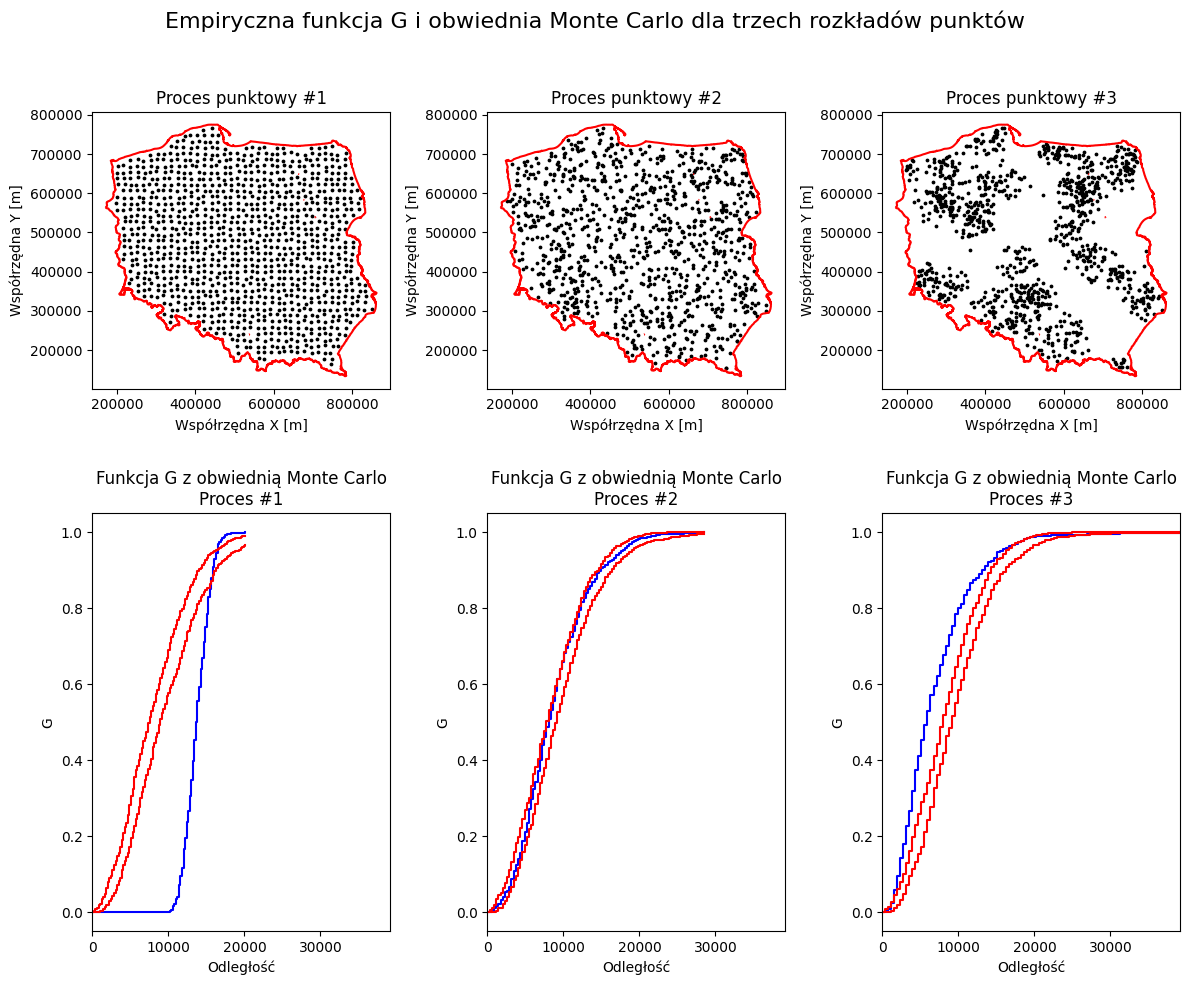

In [19]:
g_mc_1 = g_function_monte_carlo(points_1, poland.geometry.values[0], nsim=99, support=100)
g_mc_2 = g_function_monte_carlo(points_2, poland.geometry.values[0], nsim=99, support=100)
g_mc_3 = g_function_monte_carlo(points_3, poland.geometry.values[0], nsim=99, support=100)

max_x = max(g_mc_1["D"].max(), g_mc_2["D"].max(), g_mc_3["D"].max())

fig, ax = plt.subplots(2, 3, figsize=(12, 10))

poland.boundary.plot(ax=ax[0, 0], color="red")
poland.boundary.plot(ax=ax[0, 1], color="red")
poland.boundary.plot(ax=ax[0, 2], color="red")

points_1.plot(ax=ax[0, 0], markersize=3, color="black")
points_2.plot(ax=ax[0, 1], markersize=3, color="black")
points_3.plot(ax=ax[0, 2], markersize=3, color="black")

sns.lineplot(x=g_mc_1["D"], y=g_mc_1["G"], ax=ax[1, 0], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_mc_1["D"], y=g_mc_1["G_low"], ax=ax[1, 0], drawstyle="steps-post", color="red")
sns.lineplot(x=g_mc_1["D"], y=g_mc_1["G_high"], ax=ax[1, 0], drawstyle="steps-post", color="red")

sns.lineplot(x=g_mc_2["D"], y=g_mc_2["G"], ax=ax[1, 1], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_mc_2["D"], y=g_mc_2["G_low"], ax=ax[1, 1], drawstyle="steps-post", color="red")
sns.lineplot(x=g_mc_2["D"], y=g_mc_2["G_high"], ax=ax[1, 1], drawstyle="steps-post", color="red")

sns.lineplot(x=g_mc_3["D"], y=g_mc_3["G"], ax=ax[1, 2], drawstyle="steps-post", color="blue")
sns.lineplot(x=g_mc_3["D"], y=g_mc_3["G_low"], ax=ax[1, 2], drawstyle="steps-post", color="red")
sns.lineplot(x=g_mc_3["D"], y=g_mc_3["G_high"], ax=ax[1, 2], drawstyle="steps-post", color="red")

ax[0, 0].set_title("Proces punktowy #1")
ax[0, 1].set_title("Proces punktowy #2")
ax[0, 2].set_title("Proces punktowy #3")

ax[1, 0].set_title("Funkcja G z obwiednią Monte Carlo\nProces #1")
ax[1, 1].set_title("Funkcja G z obwiednią Monte Carlo\nProces #2")
ax[1, 2].set_title("Funkcja G z obwiednią Monte Carlo\nProces #3")

ax[0, 0].set_xlabel("Współrzędna X [m]")
ax[0, 1].set_xlabel("Współrzędna X [m]")
ax[0, 2].set_xlabel("Współrzędna X [m]")
ax[0, 0].set_ylabel("Współrzędna Y [m]")
ax[0, 1].set_ylabel("Współrzędna Y [m]")
ax[0, 2].set_ylabel("Współrzędna Y [m]")

for i in range(3):
    ax[1, i].set_xlim(0, max_x)
    ax[1, i].set_xlabel("Odległość")
    ax[1, i].set_ylabel("G")

fig.suptitle("Empiryczna funkcja G i obwiednia Monte Carlo dla trzech rozkładów punktów", fontsize=16)
plt.tight_layout()
plt.show()